# Workshop: run the research agent as a LangChain agent

The same research agent as the training notebook, written as a standard LangChain agent (`create_agent`) so it drops
into an existing LangChain app. Same model family, same three tools, same system prompt, same scoring code, same 13
leak-free held-out questions.

- **Model:** Kimi K3 on Fireworks serverless inference, called through the OpenAI-compatible endpoint.
- **Tools:** `search`, `open`, `answer` wrap the same `research_env.Episode` used in training, so every call is logged
  and the episode is scored with the honest reward afterwards.
- **Side by side:** runs the base model and your trained model on the same questions and scores both the same way.
  The trained model id comes from `runs/promoted_model.txt`, written by the promote cell of the training notebook.
- **Deployment (billable):** the base model runs on serverless. The trained model needs its own deployment
  (8x B300, `kimi-k3-minimal` shape). Section 2 creates it and waits until it is ready (~10-20 min); the last cell
  deletes it. Set `MODELS["tuned"] = None` to run the base model only.

About 20-30 minutes end to end, most of it waiting for the deployment. Needs only `FIREWORKS_API_KEY` in `.env` (copy `.env.example`). `GO = True`.


In [1]:
%pip install --quiet -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import collections, json, os, random, sys, time
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

HERE = Path.cwd()
if str(HERE) not in sys.path:
    sys.path.insert(0, str(HERE))
ENV_FILE = HERE / ".env"
if ENV_FILE.exists():
    for line in ENV_FILE.read_text().splitlines():
        if "=" in line and not line.strip().startswith("#"):
            k, v = line.split("=", 1)
            os.environ.setdefault(k.strip(), v.strip())
assert os.environ.get("FIREWORKS_API_KEY"), "copy .env.example to .env and set FIREWORKS_API_KEY"

DATA = HERE / "data" / "musique_ans_v1.0_dev.jsonl"
if not DATA.exists():
    import urllib.request
    DATA.parent.mkdir(exist_ok=True)
    print("downloading MuSiQue dev set (~29 MB) from Hugging Face ...")
    urllib.request.urlretrieve(
        "https://huggingface.co/datasets/dgslibisey/MuSiQue/resolve/main/musique_ans_v1.0_dev.jsonl", DATA)

from langchain.agents import create_agent
from langchain.agents.middleware import after_model, before_model
from langchain_core.messages import AIMessage, HumanMessage
from langchain_core.tools import StructuredTool
from langchain_openai import ChatOpenAI

from research_env import SYSTEM_PROMPT, Episode, drop_overlap, load_questions, score
from research_rollout import LAST_TURN_NUDGE, TEXT_REPLY_NUDGE
print("ready")


/Users/sinan/forge-workshops/.venv/lib/python3.14/site-packages/langchain_core/utils/pydantic.py:42: UserWarning: Core Pydantic V1 functionality isn't compatible with Python 3.14 or greater.
  from pydantic.v1 import BaseModel as BaseModelV1


ready


## 1. Configuration

In [3]:
GO = True

MODELS = {
    "base": "accounts/fireworks/models/kimi-k3",
    "tuned": (HERE / "runs" / "promoted_model.txt").read_text().strip(),   # from the training notebook; None to skip
}
MODELS = {k: v for k, v in MODELS.items() if v}

DRAWS = 4                                    # tries per question, same as the training notebook
MAX_TURNS = 6                                # same turn budget as training
MAX_TOKENS = 10_000
COMPLETION_BUDGET_FLOOR = 10_000
assert MAX_TOKENS >= COMPLETION_BUDGET_FLOOR
CONCURRENCY = 8

RUNS = HERE / "runs"
RUN_ID = "workshop-langchain-" + time.strftime("%Y%m%d-%H%M%S")

# the same 13 leak-free held-out questions as the training notebook
pool = load_questions(DATA, ("2hop",))
random.Random(1).shuffle(pool)
mem_test = set(json.loads((RUNS / "closedbook_kimi-k3_test_50x2.json").read_text()))
mem_train = set(json.loads((RUNS / "closedbook_kimi-k3_train_110x1.json").read_text()))
unmemorized_test = [q for q in pool[:50] if q["id"] not in mem_test][:20]
train_questions = [q for q in pool[50:160] if q["id"] not in mem_train]
questions = [q for q in unmemorized_test if len(drop_overlap(train_questions, [q])) == len(train_questions)]
print(f"{len(questions)} leak-free questions x {DRAWS} tries x {len(MODELS)} models = {len(questions) * DRAWS * len(MODELS)} episodes")


13 leak-free questions x 4 tries x 2 models = 104 episodes


## 2. Deploy the trained model and wait until it is ready

Promoted LoRA models are not served on serverless, so the trained model gets its own on-demand deployment. This
**starts billing** (8x B300) until the teardown cell at the end runs. Re-running reuses the deployment if it exists.

In [4]:
from datetime import datetime, timedelta, timezone
from fireworks import Fireworks

DEPLOY_SHAPE = "accounts/fireworks/deploymentShapes/kimi-k3-minimal"
fw = Fireworks(api_key=os.environ["FIREWORKS_API_KEY"])
deployment = None

if GO and "tuned" in MODELS:
    model = MODELS["tuned"].split("#")[0]
    account = model.split("/")[1]
    dep_id = f'{model.split("/")[-1][:40]}-{RUN_ID.split("-", 2)[-1]}'   # one deployment per notebook run; deleted ids stay reserved
    try:
        fw.deployments.create(account_id=account, base_model=model, deployment_id=dep_id, deployment_shape=DEPLOY_SHAPE,
                              min_replica_count=1, max_replica_count=1,
                              expire_time=datetime.now(timezone.utc) + timedelta(hours=3))  # backstop if teardown is skipped
        print(f"creating deployment {dep_id} for {model}")
    except Exception as exc:  # noqa: BLE001
        if "exist" not in str(exc).lower():
            raise
        print(f"reusing deployment {dep_id}")
    deployment = (account, dep_id)

    started = time.time()
    while True:
        try:
            state = fw.deployments.get(dep_id, account_id=account).state
        except Exception as exc:  # noqa: BLE001 - a network blip should not kill a long poll
            state = f"transient error: {str(exc)[:60]}"
        print(f"[{(time.time() - started) / 60:5.1f} min] {dep_id}: {state}")
        if state == "READY":
            break
        if state in ("FAILED", "DELETED", "DELETING"):
            raise RuntimeError(f"deployment {dep_id} is {state}")
        if time.time() - started > 45 * 60:
            raise TimeoutError(f"deployment {dep_id} not ready after 45 min; run the teardown cell")
        time.sleep(30)
    MODELS["tuned"] = f"{model}#accounts/{account}/deployments/{dep_id}"
    print("tuned model routed to", MODELS["tuned"])

creating deployment rsch-workshop-20261022-094238-20261022-105020 for accounts/pyroworks/models/rsch-workshop-20261022-094238
[  0.0 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  0.5 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  1.0 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  1.5 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  2.0 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  2.5 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  3.0 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  3.5 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  4.0 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  4.6 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  5.1 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  5.6 min] rsch-workshop-20261022-094238-20261022-105020: CREATING
[  6.1 min] rsch-workshop-20261022-094238-20261022-105020:

## 3. The agent: three tools around one episode

Each episode gets fresh tools bound to its own 20 documents. `answer` ends the run (`return_direct=True`).

Two small middlewares make the loop match training exactly (`research_rollout.run_rollout`): at most `MAX_TURNS` model
calls, the same "this is your last turn" nudge before the last one, and the same "use the tools" nudge when the model
replies with text instead of a tool call.

In [5]:
class ChatWithReasoning(ChatOpenAI):
    """ChatOpenAI that keeps each turn's reasoning and sends it back on later turns, as the training renderer does.
    Stock ChatOpenAI drops `reasoning_content`, so from turn 2 on the model would see a different prompt than in training."""

    def _create_chat_result(self, response, generation_info=None):
        result = super()._create_chat_result(response, generation_info)
        raw = response if isinstance(response, dict) else response.model_dump()
        for gen, choice in zip(result.generations, raw["choices"]):
            if choice["message"].get("reasoning_content"):
                gen.message.additional_kwargs["reasoning_content"] = choice["message"]["reasoning_content"]
        return result

    def _get_request_payload(self, input_, *, stop=None, **kwargs):
        payload = super()._get_request_payload(input_, stop=stop, **kwargs)
        for msg, sent in zip(self._convert_input(input_).to_messages(), payload["messages"]):
            if isinstance(msg, AIMessage) and msg.additional_kwargs.get("reasoning_content"):
                sent["reasoning_content"] = msg.additional_kwargs["reasoning_content"]
        return payload


# no reasoning_effort: the server default (thinking_effort=max) is what the training renderer uses
LLMS = {name: ChatWithReasoning(model=model, base_url="https://api.fireworks.ai/inference/v1",
                                api_key=os.environ["FIREWORKS_API_KEY"], max_tokens=MAX_TOKENS, temperature=1.0,
                                timeout=180, max_retries=2)
        for name, model in MODELS.items()}


def make_tools(ep: Episode):
    def search(query: str) -> str:
        """Search the documents. Returns the top matches with id, title and a snippet."""
        return ep.call("search", {"query": query})

    def open_doc(doc_id: int) -> str:
        """Read the full text of one document by its id."""
        return ep.call("open", {"doc_id": doc_id})

    def answer(text: str) -> str:
        """Submit the final answer: the short answer only (a name, place, date, or number), with no explanation. Ends the episode."""
        return ep.call("answer", {"text": text})

    return [StructuredTool.from_function(search, name="search"),
            StructuredTool.from_function(open_doc, name="open"),
            StructuredTool.from_function(answer, name="answer", return_direct=True)]


def model_turns(state):
    return sum(isinstance(m, AIMessage) for m in state["messages"])


@before_model(can_jump_to=["end"])
def turn_budget(state, runtime):
    n = model_turns(state)
    if n >= MAX_TURNS:
        return {"jump_to": "end"}
    if n == MAX_TURNS - 1:
        return {"messages": [HumanMessage(LAST_TURN_NUDGE)]}
    return None


@after_model(can_jump_to=["model"])
def keep_using_tools(state, runtime):
    if not state["messages"][-1].tool_calls and model_turns(state) < MAX_TURNS:
        return {"messages": [HumanMessage(TEXT_REPLY_NUDGE)], "jump_to": "model"}
    return None


def run_episode(q, name):
    ep = Episode(q)
    agent = create_agent(model=LLMS[name], tools=make_tools(ep), system_prompt=SYSTEM_PROMPT,
                         middleware=[turn_budget, keep_using_tools])
    started = time.time()
    try:
        agent.invoke({"messages": [("user", q["question"])]}, config={"recursion_limit": 10 * MAX_TURNS})
        stop = "answered" if ep.done else "no answer"
    except Exception as exc:  # noqa: BLE001 - a hit turn limit or API error is recorded, not raised
        stop = f"{type(exc).__name__}"
    return ep, score(ep), stop, time.time() - started


for name in MODELS:
    ep, s, stop, secs = run_episode(questions[0], name)
    print(f"smoke {name:5}: {[c['name'] for c in ep.calls]} -> {ep.final_answer!r} | stop {stop} | correct {s.correct:.0f} | "
          f"reward {s.reward:.2f} | {secs:.1f}s")


smoke base : ['search', 'search', 'open', 'answer'] -> 'PowerShare' | stop answered | correct 1 | reward 1.00 | 13.3s
smoke tuned: ['search', 'open', 'answer'] -> 'PowerShare' | stop answered | correct 1 | reward 1.00 | 7.3s


## 4. Run all questions

In [6]:
results = []
if GO:
    jobs = [(name, q) for name in MODELS for _ in range(DRAWS) for q in questions]
    with ThreadPoolExecutor(max_workers=CONCURRENCY) as ex:
        futures = {ex.submit(run_episode, q, name): (name, q) for name, q in jobs}
        bar = tqdm(as_completed(futures), total=len(futures), desc="langchain agent", unit="ep")
        for f in bar:
            name, q = futures[f]
            ep, s, stop, secs = f.result()
            results.append({"model": name, "id": q["id"], "question": q["question"], "gold": q["answer"],
                            "answer": ep.final_answer, "calls": [c["name"] for c in ep.calls], "stop": stop,
                            "seconds": secs, **{k: float(v) for k, v in vars(s).items()}})
            bar.set_postfix({n: f"{np.mean([r['correct'] for r in results if r['model'] == n] or [0]):.0%}" for n in MODELS})
    (RUNS / f"episodes_{RUN_ID}.jsonl").write_text("\n".join(json.dumps(r) for r in results))


langchain agent:   0%|          | 0/104 [00:00<?, ?ep/s]

## 5. Base vs tuned, scored exactly like training

model,base,tuned
episodes,52.000,52.000
"short, correct",0.250,0.212
honest reward,0.260,0.238
efficiency,0.923,0.944
tool calls,6.385,5.788
answered without reading,0.019,0.038
seconds / episode,29.526,22.536
no answer,0.000,0.000


tuned vs base: short, correct -3.8 pts (95% -12 to +0), cannot tell apart from noise


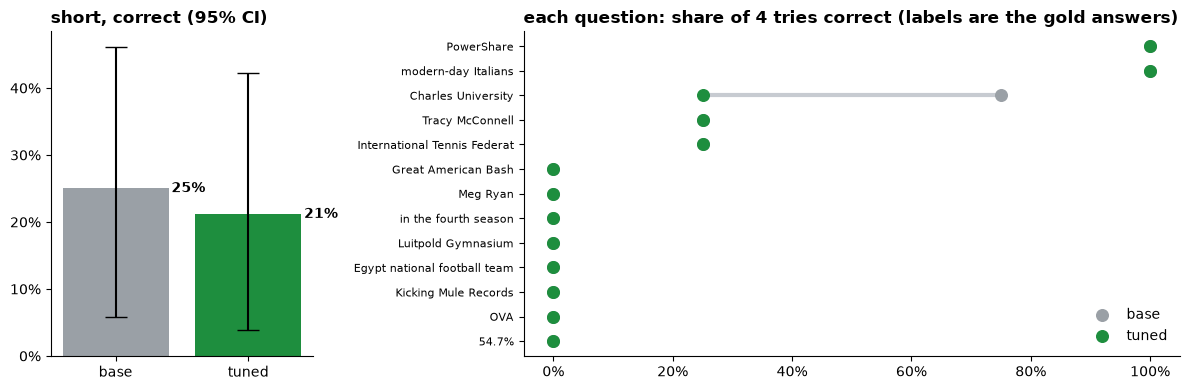

,question,gold,base answer,base correct,tuned answer,tuned correct
id,,,,,,
2hop__135653_669373,Who is the employer of the person Mach's princ...,Charles University,Charles University in Prague,0.75,University of Vienna,0.25
2hop__21103_16334,"In a 2010 study, what modern population is mos...",modern-day Italians,Modern-day Italians,1.00,Modern-day Italians,1.00
2hop__2299_38663,What percentage did the Dow Jones fall in the ...,54.7%,89%,0.00,89%,0.00
2hop__243084_523417,What is the anime that has Seta Sōjirō an inst...,OVA,Rurouni Kenshin,0.00,Rurouni Kenshin,0.00
2hop__25797_25855,What does Dell call the feature that enables d...,PowerShare,PowerShare,1.00,PowerShare,1.00
2hop__409166_152023,What record label is responsible for the perfo...,Kicking Mule Records,Real World,0.00,Real World Records,0.00
2hop__45126_807969,Which team is the highest goal scorer in EPL t...,Egypt national football team,Liverpool,0.00,Liverpool,0.00
2hop__51760_122023,What is the name of the university that educat...,Luitpold Gymnasium,University of Zurich,0.00,ETH Zurich,0.00
2hop__61714_80069,When does Pam and the person Pam marries on Th...,in the fourth season,"In the Season 4 premiere, ""Fun Run"" (they are ...",0.00,In Season 4.,0.00


In [9]:
import matplotlib.pyplot as plt

df = pd.DataFrame(results)
summary = df.groupby("model").agg(**{
    "episodes": ("correct", "size"), "short, correct": ("correct", "mean"), "honest reward": ("reward", "mean"),
    "efficiency": ("efficiency", "mean"), "tool calls": ("tool_calls", "mean"),
    "answered without reading": ("guessed", "mean"), "seconds / episode": ("seconds", "mean")}).T
summary.loc["no answer"] = df.assign(na=df["stop"] != "answered").groupby("model")["na"].mean()
display(summary[list(MODELS)].round(3))

rng = np.random.default_rng(0)
per_q = df.pivot_table(index="id", columns="model", values="correct", aggfunc="mean")
if {"base", "tuned"} <= set(per_q):
    d = (per_q["tuned"] - per_q["base"]).dropna().to_numpy()
    lo, hi = np.percentile([rng.choice(d, len(d)).mean() for _ in range(10_000)], [2.5, 97.5])
    verdict = "real" if lo > 0 or hi < 0 else "cannot tell apart from noise"
    print(f"tuned vs base: short, correct {d.mean() * 100:+.1f} pts (95% {lo * 100:+.0f} to {hi * 100:+.0f}), {verdict}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 5]})
colors = {"base": "#9aa0a6", "tuned": "#1e8e3e"}
ax = axes[0]
for k, name in enumerate(MODELS):
    pq = per_q[name].dropna().to_numpy()
    lo, hi = np.percentile([rng.choice(pq, len(pq)).mean() for _ in range(10_000)], [2.5, 97.5])
    v = df.loc[df["model"] == name, "correct"].mean()
    ax.bar(k, v, yerr=[[v - lo], [hi - v]], capsize=8, color=colors.get(name, "#70B0D8"))
    ax.text(k + 0.42, v, f"{v:.0%}", va="center", fontweight="bold")
ax.set_xticks(range(len(MODELS)), list(MODELS)); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_title("short, correct (95% CI)", loc="left", fontweight="bold")
ax = axes[1]
order = per_q.mean(axis=1).sort_values().index
y = np.arange(len(order))
if {"base", "tuned"} <= set(per_q):
    ax.hlines(y, per_q.loc[order, "base"], per_q.loc[order, "tuned"], color="#c7cbd1", lw=3)
for name in MODELS:
    ax.scatter(per_q.loc[order, name], y, s=70, color=colors.get(name, "#70B0D8"), label=name, zorder=3)
ax.set_yticks(y, [df.loc[df["id"] == i, "gold"].iloc[0][:28] for i in order], fontsize=8)
ax.set_xlim(-0.05, 1.05); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.legend(frameon=False, loc="lower right")
ax.set_title(f"each question: share of {DRAWS} tries correct (labels are the gold answers)", loc="left", fontweight="bold")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

side = (df.groupby(["id", "model"]).agg(answer=("answer", "first"), correct=("correct", "mean")).unstack("model"))
side.columns = [f"{m} {c}" for c, m in side.columns]
side = side.join(df.groupby("id")[["question", "gold"]].first())
display(side[["question", "gold"] + [f"{m} {c}" for m in MODELS for c in ("answer", "correct")]])


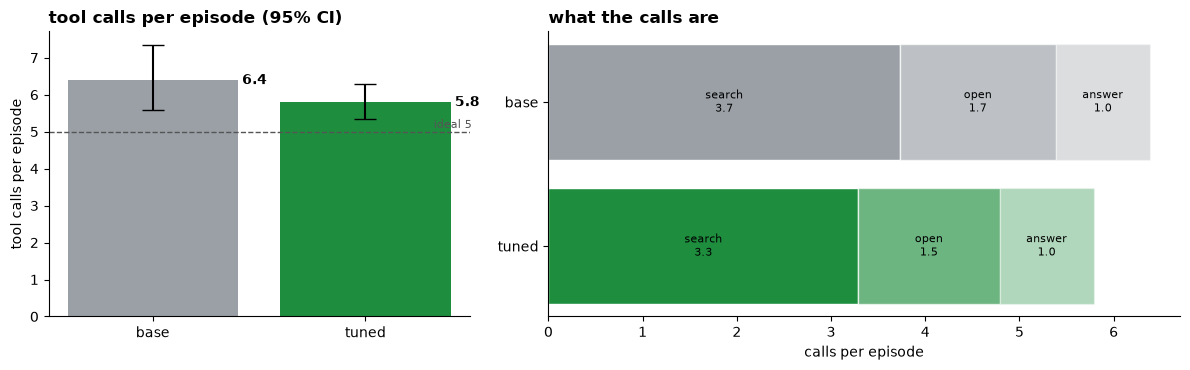

In [10]:
# tool calls: how much work each model does per question (ideal path = 5: search + open per hop, then answer)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [2, 3]})
colors = {"base": "#9aa0a6", "tuned": "#1e8e3e"}

ax = axes[0]
for k, name in enumerate(MODELS):
    calls = df.loc[df["model"] == name, "tool_calls"].to_numpy()
    lo, hi = np.percentile([rng.choice(calls, len(calls)).mean() for _ in range(10_000)], [2.5, 97.5])
    ax.bar(k, calls.mean(), yerr=[[calls.mean() - lo], [hi - calls.mean()]], capsize=8, color=colors.get(name, "#70B0D8"))
    ax.text(k + 0.42, calls.mean(), f"{calls.mean():.1f}", va="center", fontweight="bold")
ax.axhline(5, ls="--", color="#555", lw=1); ax.text(len(MODELS) - 0.5, 5.1, "ideal 5", ha="right", fontsize=8, color="#555")
ax.set_xticks(range(len(MODELS)), list(MODELS)); ax.set_ylabel("tool calls per episode")
ax.set_title("tool calls per episode (95% CI)", loc="left", fontweight="bold")

ax = axes[1]
kinds = ["search", "open", "answer"]
shades = {"search": 1.0, "open": 0.65, "answer": 0.35}
left = np.zeros(len(MODELS))
for kind in kinds:
    vals = np.array([np.mean([c.count(kind) for c in df.loc[df["model"] == name, "calls"]]) for name in MODELS])
    ax.barh(range(len(MODELS)), vals, left=left, color=[colors.get(n, "#70B0D8") for n in MODELS], alpha=shades[kind],
            edgecolor="white")
    for y, (x0, v) in enumerate(zip(left, vals)):
        if v >= 0.4:
            ax.text(x0 + v / 2, y, f"{kind}\n{v:.1f}", ha="center", va="center", fontsize=8)
    left += vals
ax.set_yticks(range(len(MODELS)), list(MODELS)); ax.invert_yaxis(); ax.set_xlabel("calls per episode")
ax.set_title("what the calls are", loc="left", fontweight="bold")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); plt.show()

## 6. Tear down the deployment (stops billing)

In [8]:
if deployment:
    account, dep_id = deployment
    try:
        fw.deployments.delete(dep_id, account_id=account, ignore_checks=True)
        print(f"deleted {dep_id}")
    except Exception as exc:  # noqa: BLE001
        print(f"could not delete {dep_id}: {str(exc)[:160]} -- delete it in the Fireworks console")
else:
    print("no deployment to delete")

deleted rsch-workshop-20261022-094238-20261022-105020
